In [1]:
import jax
import jax.numpy as jnp
from flax import nnx

from hcnn.environment import Environment
from hcnn.optimization import OptimizationSolverOSQP
from hcnn.policy.policy_mlp import PolicyMLP
from hcnn.projection import ProjectionNoSubstitutionNoTerminal
from hcnn.system_constraints import SystemConstraintsSphere
from hcnn.system_dynamics import SystemDynamicsLinear

center = jnp.array([1, 1])
radius = 3.0

state_matrix = jnp.array([[1.0, -1.0], [1.0, 0.0]])
input_matrix = jnp.array([[1.0], [0.0]])
state_cost = jnp.eye(2)
input_cost = jnp.eye(1)
system = SystemDynamicsLinear.factory(state_matrix, input_matrix)
rngs = nnx.Rngs(42, dropout=1)
policy = PolicyMLP.factory([2, 3, 3, 1], 0.2, rngs=rngs)
constraint = SystemConstraintsSphere.factory(center=center, radius=radius)
projection = ProjectionNoSubstitutionNoTerminal.factory(
    system, constraint, policy, horizon=10, relaxation_penalty=5.0
)
solver = OptimizationSolverOSQP(tol=1e-3, max_iter=1e3)
environment = Environment(system, policy, projection, solver)

In [2]:
nnx.display(policy)

In [3]:
view_range = 5.0
samples_per_axis = 20
axis_samples = jnp.linspace(-view_range, view_range, samples_per_axis)
X, Y = jnp.meshgrid(axis_samples, axis_samples, indexing="xy")
states = jnp.stack((X.flatten(), Y.flatten()), axis=-1)
next_states = jax.vmap(
    lambda state: environment.step(state, rngs=nnx.Rngs(12)), in_axes=(0), out_axes=0
)(states)
difference = next_states - states

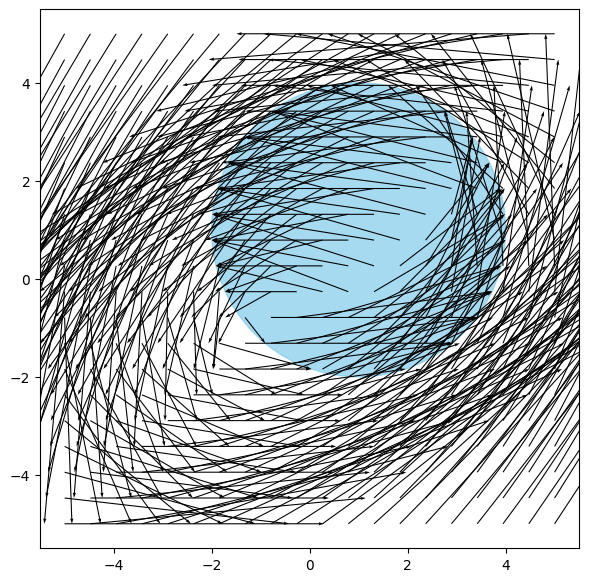

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 7), dpi=100)
ax.set_aspect("equal")
circle = plt.Circle(center, radius, color="skyblue", alpha=0.75, label="constraint")
ax.add_artist(circle)
plt.quiver(
    states[:, 0],
    states[:, 1],
    difference[:, 0],
    difference[:, 1],
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.002,
)
plt.show()

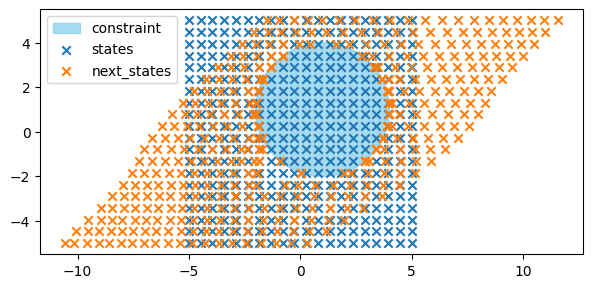

In [5]:
fig, ax = plt.subplots(figsize=(7, 7), dpi=100)
ax.set_aspect("equal")
circle = plt.Circle(center, radius, color="skyblue", alpha=0.75, label="constraint")
ax.add_artist(circle)
plt.scatter(states[:, 0], states[:, 1], marker="x", label="states")
plt.scatter(next_states[:, 0], next_states[:, 1], marker="x", label="next_states")
plt.legend()
plt.show()

In [6]:
policy_params = nnx.state(policy, nnx.Param)
problem = projection.get_problem(
    initial_state=center, policy_params=policy_params, rngs=nnx.Rngs(12)
)
x_star = solver.solve(problem)
rollout = projection.get_rollout(x_star)

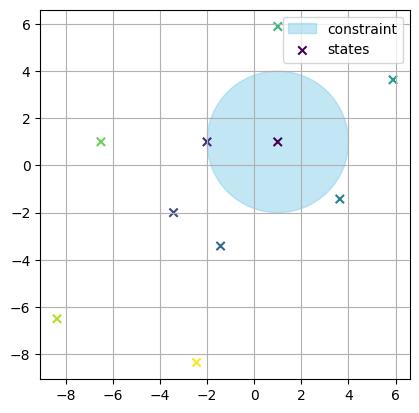

In [7]:
# Create figure and axis
fig, ax = plt.subplots()
circle = plt.Circle(center, radius, color="skyblue", alpha=0.5, label="constraint")
ax.add_artist(circle)
order = jnp.arange(len(rollout.states))
plt.scatter(
    rollout.states[:, 0], rollout.states[:, 1], c=order, cmap="viridis", marker="x", label="states"
)
ax.set_aspect("equal")
plt.legend()
plt.grid(True)
plt.show()

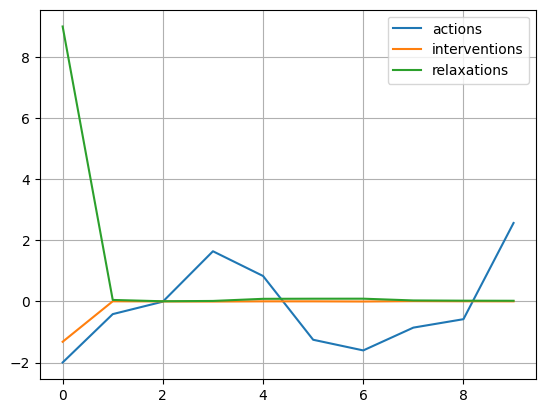

In [8]:
fig, ax = plt.subplots()
plt.plot(rollout.actions, label="actions")
plt.plot(rollout.interventions, label="interventions")
plt.plot(rollout.relaxations, label="relaxations")
plt.legend()
plt.grid(True)
plt.show()